# Big-10 Index Analysis
Point-in-Time (PIT) Portfolio Construction and Analysis

This notebook demonstrates PIT analysis using WRDS data to construct portfolios of the 10 largest U.S. companies by market capitalization.

In [1]:
# Import libraries
import wrds
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Establish WRDS connection
# Note: This will prompt for your WRDS credentials
conn = wrds.Connection(wrds_username='cpehlivanian')

Loading library list...
Done


## Task 1: Top 10 Companies by Year

In [3]:
# Query to get the top 10 companies by market cap at end of each year
# This query implements PIT logic by:
# 1. Finding the last trading day of each year
# 2. Restricting to common stock (securitytype = 'EQTY', sharetype = 'NS'),
#    which excludes ETFs such as SPY and ADRs such as BABA
# 3. Summing market cap across share classes by company (permco), so that
#    GOOG/GOOGL count as one company
# 4. Ranking companies by market cap on that specific date and keeping the top 10
# Each row is one share class (permno); a company with two classes has two rows.
query_PIT = """
WITH last_trading_days AS (
    SELECT
        EXTRACT(YEAR FROM dlycaldt) AS year,
        MAX(dlycaldt) AS last_date
    FROM
        crsp_a_stock.wrds_dsfv2_query
    WHERE
        EXTRACT(YEAR FROM dlycaldt) BETWEEN 2012 AND 2024
    GROUP BY
        EXTRACT(YEAR FROM dlycaldt)
),
common_stock AS (
    SELECT
        a.dlycaldt, a.permno, a.permco, a.ticker, a.dlycap
    FROM
        crsp_a_stock.wrds_dsfv2_query a
    JOIN
        last_trading_days b ON a.dlycaldt = b.last_date
    WHERE
        a.dlycap IS NOT NULL
        AND a.securitytype = 'EQTY'
        AND a.sharetype = 'NS'
),
ranked_companies AS (
    SELECT
        dlycaldt, permco,
        SUM(dlycap) AS company_cap,
        ROW_NUMBER() OVER (PARTITION BY dlycaldt ORDER BY SUM(dlycap) DESC) AS rank
    FROM
        common_stock
    GROUP BY
        dlycaldt, permco
)
SELECT
    c.dlycaldt, c.permno, c.permco, c.ticker, c.dlycap, r.company_cap, r.rank
FROM
    common_stock c
JOIN
    ranked_companies r ON c.dlycaldt = r.dlycaldt AND c.permco = r.permco
WHERE
    r.rank <= 10
ORDER BY
    c.dlycaldt, r.rank, c.dlycap DESC;
"""

# Execute the query
df_pit = conn.raw_sql(query_PIT)

# Convert date column and display results
df_pit['dlycaldt'] = pd.to_datetime(df_pit['dlycaldt'])
print("Top 10 Companies by Market Cap at End of Each Year:")
print(df_pit)

Top 10 Companies by Market Cap at End of Each Year:
      dlycaldt  permno  permco ticker        dlycap   company_cap  rank
0   2012-12-31   14593       7   AAPL  499695984.43  499695984.43     1
1   2012-12-31   11850   20678    XOM  394611136.65  394611136.65     2
2   2012-12-31   55976   21880    WMT  228245588.74  228245588.74     3
3   2012-12-31   10107    8048   MSFT   223667027.8   223667027.8     4
4   2012-12-31   17778     540    BRK   123201140.0   221852572.1     5
..         ...     ...     ...    ...           ...           ...   ...
149 2024-12-31   13407   54084   META  1282266900.0  1282266900.0     7
150 2024-12-31   93002   53196   AVGO  1086402240.0  1086402240.0     8
151 2024-12-31   83443     540    BRK  602158456.16  978026296.16     9
152 2024-12-31   17778     540    BRK   375867840.0  978026296.16     9
153 2024-12-31   50876   21102    LLY   732871952.0   732871952.0    10

[154 rows x 7 columns]


In [4]:
df_pit.dtypes

dlycaldt       datetime64[ns]
permno                  Int64
permco                  Int64
ticker         string[python]
dlycap                Float64
company_cap           Float64
rank                    Int64
dtype: object

In [5]:
df_pit.iloc[0]['dlycaldt']

Timestamp('2012-12-31 00:00:00')

In [6]:
import pandas as pd

In [7]:
df_pit[df_pit['dlycaldt'] == pd.Timestamp('2024-12-31 00:00:00')]

,dlycaldt,permno,permco,ticker,dlycap,company_cap,rank
142,2024-12-31,14593,7,AAPL,3766499857.02,3766499857.02,1
143,2024-12-31,86580,16382,NVDA,3288762100.0,3288762100.0,2
144,2024-12-31,10107,8048,MSFT,3133802341.5,3133802341.5,3
145,2024-12-31,84788,15473,AMZN,2323998270.0,2323998270.0,4
146,2024-12-31,90319,45483,GOOGL,1104565500.0,2154842100.0,5
147,2024-12-31,14542,45483,GOOG,1050276600.0,2154842100.0,5
148,2024-12-31,93436,53453,TSLA,1298958225.28,1298958225.28,6
149,2024-12-31,13407,54084,META,1282266900.0,1282266900.0,7
150,2024-12-31,93002,53196,AVGO,1086402240.0,1086402240.0,8
151,2024-12-31,83443,540,BRK,602158456.16,978026296.16,9


## Task 2: Turnover Analysis

In [8]:
# Query for monthly data to calculate turnover
# Knowledge Date consideration: We use end-of-month data that would have been
# available to investors at that time
# Companies are identified by permco rather than ticker, so a ticker change
# (e.g. FB -> META in 2022) is not counted as turnover
query_EOM = """
WITH last_trading_days AS (
    SELECT
        EXTRACT(YEAR FROM dlycaldt) AS year,
        EXTRACT(MONTH FROM dlycaldt) AS month,
        MAX(dlycaldt) AS last_date
    FROM
        crsp_a_stock.wrds_dsfv2_query
    WHERE
        dlycaldt BETWEEN '2012-12-31' AND '2024-12-31'
    GROUP BY
        EXTRACT(YEAR FROM dlycaldt), EXTRACT(MONTH FROM dlycaldt)
),
ranked_companies AS (
    SELECT
        a.dlycaldt, a.permco,
        SUM(a.dlycap) AS company_cap,
        ROW_NUMBER() OVER (PARTITION BY a.dlycaldt ORDER BY SUM(a.dlycap) DESC) AS rank
    FROM
        crsp_a_stock.wrds_dsfv2_query a
    JOIN
        last_trading_days b ON a.dlycaldt = b.last_date
    WHERE
        a.dlycap IS NOT NULL
        AND a.securitytype = 'EQTY'
        AND a.sharetype = 'NS'
    GROUP BY
        a.dlycaldt, a.permco
)
SELECT
    dlycaldt, permco, company_cap
FROM
    ranked_companies
WHERE
    rank <= 10
ORDER BY
    dlycaldt, company_cap DESC;
"""

# Execute query and calculate turnover
df_eom = conn.raw_sql(query_EOM)
df_eom['dlycaldt'] = pd.to_datetime(df_eom['dlycaldt'])

# Calculate turnover between consecutive months
turnover_data = []
eom_dates = sorted(df_eom['dlycaldt'].unique())

for i in range(1, len(eom_dates)):
    current_companies = set(df_eom[df_eom['dlycaldt'] == eom_dates[i]]['permco'])
    previous_companies = set(df_eom[df_eom['dlycaldt'] == eom_dates[i-1]]['permco'])

    # Count companies that changed (entered or exited)
    changes = len(current_companies.symmetric_difference(previous_companies))
    turnover = changes / 10  # Normalize by total positions

    turnover_data.append({'date': eom_dates[i], 'turnover': turnover})

df_turnover = pd.DataFrame(turnover_data)

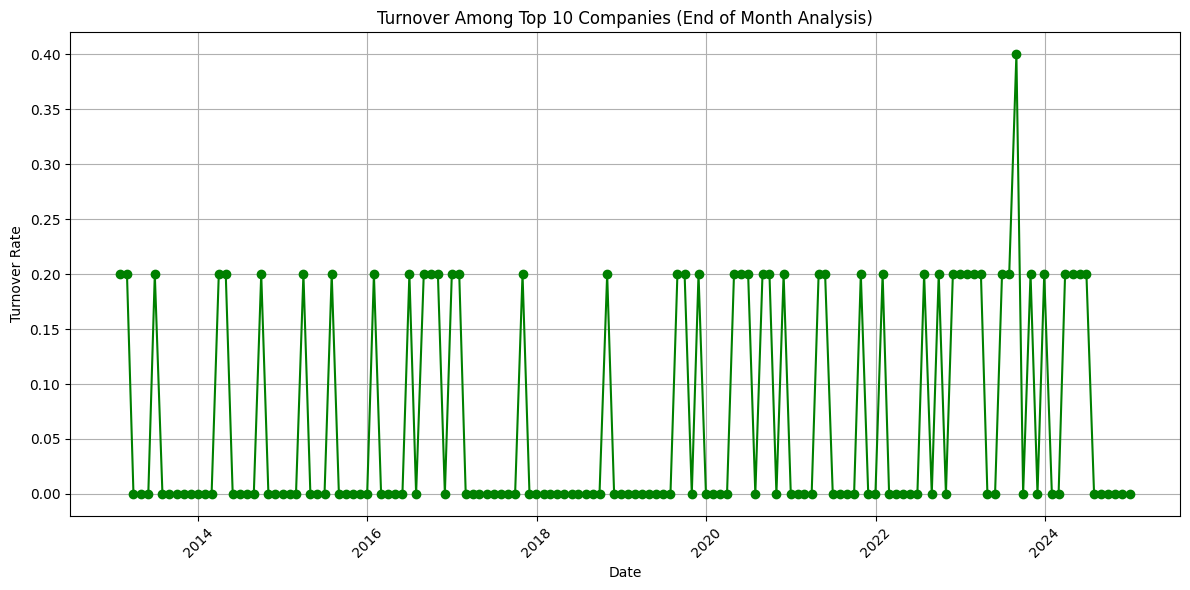

Average monthly turnover: 6.53%
Maximum monthly turnover: 40.00%


In [9]:
# Plot turnover over time
plt.figure(figsize=(12, 6))
plt.plot(df_turnover['date'], df_turnover['turnover'], marker='o', linestyle='-', color='g')
plt.title('Turnover Among Top 10 Companies (End of Month Analysis)')
plt.xlabel('Date')
plt.ylabel('Turnover Rate')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Average monthly turnover: {df_turnover['turnover'].mean():.2%}")
print(f"Maximum monthly turnover: {df_turnover['turnover'].max():.2%}")

## Task 3A: Non-PIT Portfolio Analysis

In [10]:
# Get the top 10 companies as of end of 2024 (from the PIT selection above)
top10_2024 = df_pit[df_pit['dlycaldt'].dt.year == 2024]
print("Top 10 companies as of end of 2024:")
print(top10_2024[['ticker', 'permno', 'permco', 'dlycap']])

# Store the permnos for portfolio construction
# We select by permno, not ticker: tickers change over time (META traded as FB
# until 2022) and get reused (GOOG was the class A ticker before April 2014)
nonpit_permnos = top10_2024['permno'].tolist()
print(f"\nNon-PIT portfolio will hold: {top10_2024['ticker'].tolist()}")

Top 10 companies as of end of 2024:
    ticker  permno  permco         dlycap
142   AAPL   14593       7  3766499857.02
143   NVDA   86580   16382   3288762100.0
144   MSFT   10107    8048   3133802341.5
145   AMZN   84788   15473   2323998270.0
146  GOOGL   90319   45483   1104565500.0
147   GOOG   14542   45483   1050276600.0
148   TSLA   93436   53453  1298958225.28
149   META   13407   54084   1282266900.0
150   AVGO   93002   53196   1086402240.0
151    BRK   83443     540   602158456.16
152    BRK   17778     540    375867840.0
153    LLY   50876   21102    732871952.0

Non-PIT portfolio will hold: ['AAPL', 'NVDA', 'MSFT', 'AMZN', 'GOOGL', 'GOOG', 'TSLA', 'META', 'AVGO', 'BRK', 'BRK', 'LLY']


In [11]:
# Get daily return and market cap data for these companies over the full period
# dlyret is the total return (adjusted for splits and including dividends);
# computing dlyprc/dlyprevprc - 1 is wrong on split days because dlyprevprc
# is not split-adjusted
permnos_str = ", ".join(str(p) for p in nonpit_permnos)
query_nonpit_data = f"""
SELECT dlycaldt, permno, permco, ticker, dlyret, dlyprevcap
FROM crsp_a_stock.wrds_dsfv2_query
WHERE permno IN ({permnos_str})
AND dlycaldt BETWEEN '2013-01-01' AND '2024-12-31'
ORDER BY dlycaldt, permno;
"""

df_nonpit = conn.raw_sql(query_nonpit_data)
df_nonpit['dlycaldt'] = pd.to_datetime(df_nonpit['dlycaldt'])
df_nonpit['daily_return'] = df_nonpit['dlyret'].astype(float)
df_nonpit = df_nonpit.dropna(subset=['daily_return', 'dlyprevcap'])

print(f"Loaded {len(df_nonpit)} daily observations for Non-PIT portfolio")

Loaded 35924 daily observations for Non-PIT portfolio


In [12]:
# Calculate market-cap weighted portfolio returns
# Note: We weight each day's return by the PREVIOUS day's market cap (dlyprevcap);
# using the same day's cap would put more weight on stocks that went up that day
df_nonpit['total_market_cap'] = df_nonpit.groupby('dlycaldt')['dlyprevcap'].transform('sum')
df_nonpit['market_cap_weight'] = df_nonpit['dlyprevcap'] / df_nonpit['total_market_cap']
df_nonpit['weighted_return'] = df_nonpit['daily_return'] * df_nonpit['market_cap_weight']

# Aggregate to portfolio level
nonpit_portfolio = df_nonpit.groupby('dlycaldt')['weighted_return'].sum().reset_index()
nonpit_portfolio.columns = ['date', 'portfolio_return']

# Calculate cumulative returns
nonpit_portfolio['cumulative_return'] = (1 + nonpit_portfolio['portfolio_return']).cumprod() - 1

# Final return
final_nonpit_return = nonpit_portfolio['cumulative_return'].iloc[-1]
print(f"Non-PIT Market-Cap Weighted Portfolio Total Return (2013-2024): {final_nonpit_return:.2%}")

Non-PIT Market-Cap Weighted Portfolio Total Return (2013-2024): 1638.70%


In [13]:
# Equal-weighted version for comparison (rebalanced daily, equal weight per company)
# A company with two share classes (GOOG/GOOGL) gets one weight, split across
# its classes by market cap
df_nonpit['cap_x_return'] = df_nonpit['dlyprevcap'] * df_nonpit['daily_return']
company_daily = df_nonpit.groupby(['dlycaldt', 'permco'])[['cap_x_return', 'dlyprevcap']].sum()
company_daily['company_return'] = company_daily['cap_x_return'] / company_daily['dlyprevcap']

nonpit_equal = company_daily.groupby('dlycaldt')['company_return'].mean().reset_index()
nonpit_equal.columns = ['date', 'portfolio_return']
nonpit_equal['cumulative_return'] = (1 + nonpit_equal['portfolio_return']).cumprod() - 1

final_nonpit_equal_return = nonpit_equal['cumulative_return'].iloc[-1]
print(f"Non-PIT Equal-Weighted Portfolio Total Return (2013-2024): {final_nonpit_equal_return:.2%}")

Non-PIT Equal-Weighted Portfolio Total Return (2013-2024): 4733.49%


## Task 3B: PIT Portfolio Analysis

In [14]:
# The PIT portfolio rebalances annually to the top 10 companies
# We'll calculate returns year by year, using each year's top 10 companies
# selected at the previous year-end

# Get daily returns for every security that was ever in the PIT portfolio
pit_permnos_str = ", ".join(str(p) for p in df_pit['permno'].unique())
query_pit_data = f"""
SELECT dlycaldt, permno, dlyret
FROM crsp_a_stock.wrds_dsfv2_query
WHERE permno IN ({pit_permnos_str})
AND dlycaldt BETWEEN '2013-01-01' AND '2024-12-31';
"""
df_pit_daily = conn.raw_sql(query_pit_data)
df_pit_daily['dlycaldt'] = pd.to_datetime(df_pit_daily['dlycaldt'])
df_pit_daily['year'] = df_pit_daily['dlycaldt'].dt.year
df_pit_daily['dlyret'] = df_pit_daily['dlyret'].astype(float)

# Buy-and-hold return of each security over each calendar year:
# compound the daily total returns
annual_returns = (
    df_pit_daily.groupby(['permno', 'year'])['dlyret']
    .apply(lambda r: (1 + r).prod() - 1)
    .rename('annual_return')
    .reset_index()
)

pit_annual_returns = []

# Process each year from 2013 to 2024 (starting 2013 since we need 2012 data for weights)
for year in range(2013, 2025):
    # Get the top 10 companies for the previous year-end (this is our PIT selection)
    year_top10 = df_pit[df_pit['dlycaldt'].dt.year == (year-1)].copy()

    # Weight each security by its market cap at the previous year-end
    total_cap = year_top10['dlycap'].sum()
    year_top10['weight'] = year_top10['dlycap'] / total_cap

    # Return from holding these securities over the whole of 'year'
    # This represents what an investor would have earned following PIT methodology
    year_top10 = year_top10.merge(
        annual_returns[annual_returns['year'] == year], on='permno', how='left'
    )
    year_top10['weighted_return'] = year_top10['annual_return'] * year_top10['weight']

    portfolio_return = year_top10['weighted_return'].sum()
    pit_annual_returns.append(portfolio_return)

    print(f"Year {year}: Portfolio Return = {portfolio_return:.2%}")
    print(f"  Companies: {year_top10['ticker'].tolist()}")

# Calculate total cumulative return
pit_cumulative = (pd.Series([1+x for x in pit_annual_returns]).cumprod() - 1.).iloc[-1]
print(f"\nPIT Portfolio Total Return (2013-2024): {pit_cumulative:.2%}")

Year 2013: Portfolio Return = 20.83%
  Companies: ['AAPL', 'XOM', 'WMT', 'MSFT', 'BRK', 'BRK', 'GE', 'IBM', 'CVX', 'JNJ', 'T']
Year 2014: Portfolio Return = 13.41%
  Companies: ['AAPL', 'XOM', 'GOOG', 'MSFT', 'BRK', 'BRK', 'GE', 'JNJ', 'WMT', 'CVX', 'WFC']
Year 2015: Portfolio Return = 2.96%
  Companies: ['AAPL', 'XOM', 'MSFT', 'BRK', 'BRK', 'GOOG', 'GOOGL', 'JNJ', 'WFC', 'WMT', 'GE', 'PG']
Year 2016: Portfolio Return = 13.29%
  Companies: ['AAPL', 'GOOG', 'GOOGL', 'MSFT', 'BRK', 'BRK', 'XOM', 'AMZN', 'GE', 'JNJ', 'WFC', 'JPM']
Year 2017: Portfolio Return = 25.93%
  Companies: ['AAPL', 'GOOG', 'GOOGL', 'MSFT', 'BRK', 'BRK', 'XOM', 'AMZN', 'JNJ', 'JPM', 'GE', 'WFC']
Year 2018: Portfolio Return = 0.13%
  Companies: ['AAPL', 'GOOG', 'GOOGL', 'MSFT', 'AMZN', 'BRK', 'BRK', 'FB', 'JNJ', 'JPM', 'XOM', 'BAC']
Year 2019: Portfolio Return = 40.56%
  Companies: ['MSFT', 'AAPL', 'AMZN', 'GOOG', 'GOOGL', 'BRK', 'BRK', 'JNJ', 'JPM', 'FB', 'XOM', 'WMT']
Year 2020: Portfolio Return = 42.18%
  Companie

## Task 4: Performance Analysis

In [16]:
# Create a summary comparison
print("=" * 60)
print("PORTFOLIO PERFORMANCE COMPARISON (2013-2024)")
print("=" * 60)
print(f"Non-PIT Market-Cap Weighted:  {final_nonpit_return:>8.2%}")
print(f"Non-PIT Equal-Weighted:       {final_nonpit_equal_return:>8.2%}")
print(f"PIT Market-Cap Weighted:      {pit_cumulative:>8.2%}")
print("=" * 60)

print("\nKey Insights:")
print("• Non-PIT portfolios benefit from SURVIVORSHIP BIAS")
print("• They select companies known to be successful in 2024")
print("• PIT portfolio reflects REAL-TIME investment decisions")
print("• PIT rebalancing may capture companies at their peak")
print("• Transaction costs and timing issues affect PIT performance")

PORTFOLIO PERFORMANCE COMPARISON (2013-2024)
Non-PIT Market-Cap Weighted:  1638.70%
Non-PIT Equal-Weighted:       4733.49%
PIT Market-Cap Weighted:       653.31%

Key Insights:
• Non-PIT portfolios benefit from SURVIVORSHIP BIAS
• They select companies known to be successful in 2024
• PIT portfolio reflects REAL-TIME investment decisions
• PIT rebalancing may capture companies at their peak
• Transaction costs and timing issues affect PIT performance


In [ ]:
# Close connection
conn.close()